# Directed edge betweenness

Loads Medellin's drive graph, adds travel-time weights, computes directed edge betweenness, saves GraphML outputs, and plots high-betweenness links.

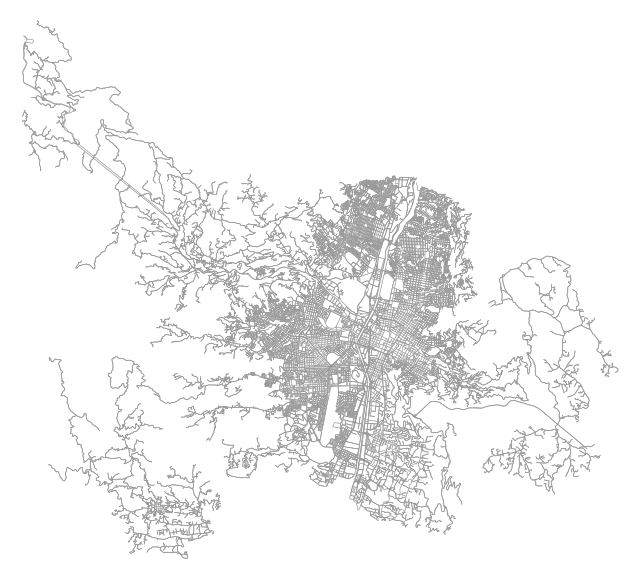

In [4]:
# Prepare Medellin road network and travel-time weights.
import osmnx as ox
import matplotlib.pyplot as plt
import geopandas as gpd
from pathlib import Path

def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "edge_importance_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
EDGE_IMPORTANCE_ROOT = REPO_ROOT / "edge_importance_ph"
ROAD_IMPORTANCE_DIR = EDGE_IMPORTANCE_ROOT / "calculate_road_importance"

place_name = "Medellin, Colombia"

# Obtener geometría de la ciudad
gdf_place = ox.geocode_to_gdf(place_name)

# Proyectar a CRS métrico
gdf_proj = ox.projection.project_gdf(gdf_place)

# Calcular centroide correctamente
center_proj = gdf_proj.geometry.centroid.iloc[0]

# Crear GeoDataFrame con el centroide y volver a lat/lon
center_gdf = gpd.GeoDataFrame(geometry=[center_proj], crs=gdf_proj.crs).to_crs(epsg=4326)
center_point = center_gdf.geometry.iloc[0]


center_lat = center_point.y
center_lon = center_point.x

# Descargar grafo de referencia alrededor del centroide
G = ox.graph_from_point(
    (center_lat, center_lon),
    dist=7500,
    network_type="drive"
)

graph_path = ROAD_IMPORTANCE_DIR / "medellin_drive_with_elevation.graphml"

# Usar el GraphML local para el análisis
G = ox.load_graphml(graph_path)


# Normalizar velocidad y calcular tiempo de viaje por arista
for u, v, k, data in G.edges(keys=True, data=True):
    maxspeed = 40

    if "maxspeed" in data:
        raw_maxspeed = data["maxspeed"]

        if isinstance(raw_maxspeed, list):
            values = []
            for s in raw_maxspeed:
                try:
                    values.append(int(str(s).split()[0]))
                except (ValueError, TypeError):
                    continue
            if values:
                maxspeed = min(values)

        elif isinstance(raw_maxspeed, str):
            try:
                maxspeed = int(raw_maxspeed.split()[0])
            except ValueError:
                maxspeed = 40

        else:
            try:
                maxspeed = int(raw_maxspeed)
            except (ValueError, TypeError):
                maxspeed = 40

    if maxspeed == 0:
        maxspeed = 40

    data["maxspeed"] = maxspeed
    data["travel_time"] = data["length"] / (maxspeed * 1000 / 3600)

# Visualizar la red base
fig, ax = ox.plot_graph(G, node_size=0, edge_linewidth=0.5, bgcolor="white")
plt.show()

In [5]:

import networkx as nx
G_directed = nx.DiGraph(G)
# Revisar atributos de una arista
u, v, data = list(G_directed.edges(data=True))[0]
print(data)


{'osmid': 570316480, 'highway': 'secondary', 'lanes': '3', 'maxspeed': 50, 'name': 'Calle 10', 'oneway': True, 'reversed': False, 'length': 42.6922259534499, 'weight': '0.8538445190689979', 'travel_time': 3.0738402686483925}


In [6]:
# Contar aristas y nodos del grafo cargado.
print(len(G.edges))
print(len(G.nodes))

42829
18086


In [7]:
# Calcular betweenness de aristas en grafo dirigido con peso de tiempo.
# Convertir MultiDiGraph a DiGraph simple para NetworkX.
import networkx as nx
G_directed = nx.DiGraph(G)
nx_edge_bc = nx.edge_betweenness_centrality(G_directed, weight='travel_time', normalized=False)

for (u, v), score in nx_edge_bc.items():
    G_directed[u][v]['betweenness'] = score

In [9]:
# Guardar betweenness en los grafos de salida.
# Mapear puntajes al grafo OSMnx original.
for u, v, k in G.edges(keys=True):
    G.edges[u, v, k]['betweenness'] = nx_edge_bc.get((u, v), 0)

output_dir = ROAD_IMPORTANCE_DIR / 'mde_example'
output_dir.mkdir(parents=True, exist_ok=True)
ox.save_graphml(G, output_dir / 'medellin_completa_osmnx.graphml')

# Convertir atributos no serializables antes de guardar con NetworkX.
GRAPHML_TYPES = (bool, int, float, str)
G_save = G_directed.copy()
for _, _, data in G_save.edges(data=True):
    for k, v in list(data.items()):
        if not isinstance(v, GRAPHML_TYPES):
            data[k] = str(v)
for _, data in G_save.nodes(data=True):
    for k, v in list(data.items()):
        if not isinstance(v, GRAPHML_TYPES):
            data[k] = str(v)
nx.write_graphml(G_save, output_dir / 'medellin_completa.graphml')

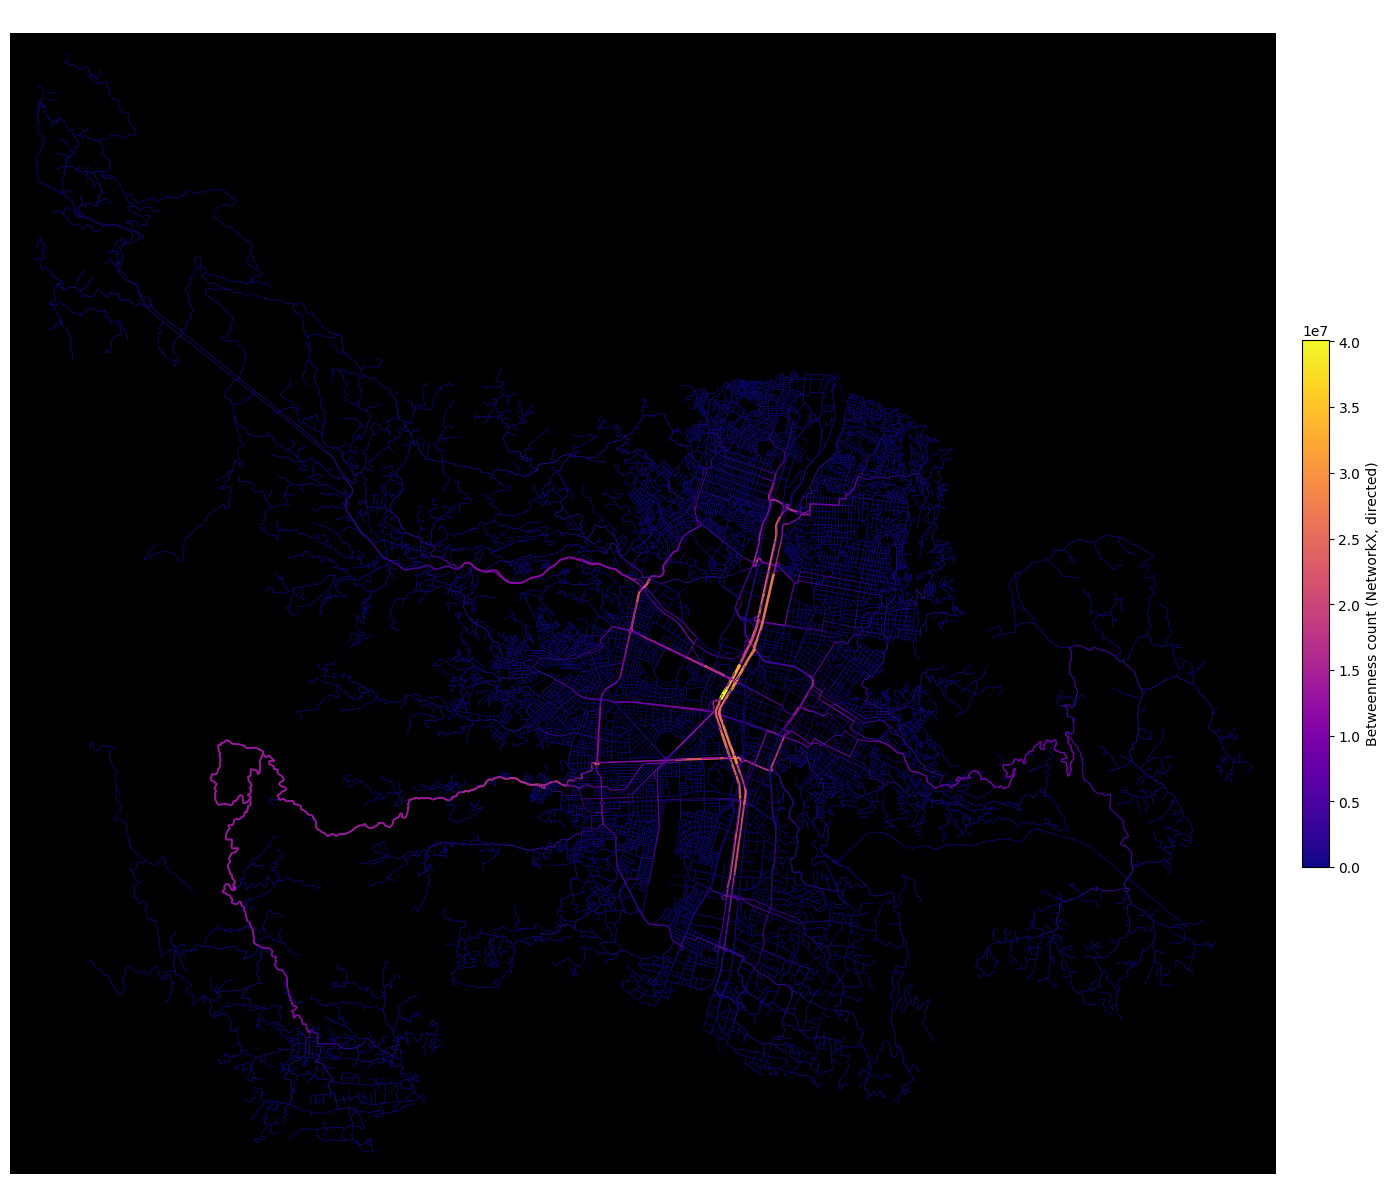

In [10]:
# Mapear puntajes dirigidos al MultiDiGraph para graficarlos.
import numpy as np
nx_directed_scores = []
for u, v, k in G.edges(keys=True):
    nx_directed_scores.append(nx_edge_bc.get((u, v), 0))

nx_scores = np.array(nx_directed_scores, dtype=float)
nx_scores_norm = (nx_scores - nx_scores.min()) / (nx_scores.max() - nx_scores.min() + 1e-9)

cmap = plt.cm.plasma
edge_colors = [cmap(s) for s in nx_scores_norm]
edge_widths = [0.3 + 2.5 * s for s in nx_scores_norm]

fig, ax = ox.plot_graph(
    G,
    edge_color=edge_colors,
    edge_linewidth=edge_widths,
    node_size=0,
    bgcolor='black',
    show=False,
    close=False,
    figsize=(14, 14)
)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=nx_scores.min(), vmax=nx_scores.max()))
sm.set_array([])
plt.colorbar(sm, ax=ax, fraction=0.02, pad=0.02, label='Betweenness count (NetworkX, directed)')
ax.set_title('Edge Betweenness Centrality (NetworkX, Directed) - Medellin', color='white', fontsize=14)
plt.tight_layout()
# plt.savefig(ROAD_IMPORTANCE_DIR / 'experiment_bounding_city' / 'figs' / 'norte' / 'chengdu.pdf', dpi=300, bbox_inches='tight')
plt.show()